# Генерация лиц — optimized: обучение с нуля

Это отдельная оптимизированная версия `Faces_Diffusion_Colab.ipynb`.
Задача и архитектура прежние: безусловная генерация RGB-лиц 64×64, U-Net + EDM.

Реализованы оптимизации 1–4 из разбора:

1. Смешанная точность AMP FP16 для U-Net на CUDA; EDM, loss и attention softmax — FP32.
2. Подготовленные изображения хранятся в RAM как uint8; случайное отражение остаётся случайным.
3. Метрики накапливаются на устройстве, вывод обновляется раз в `LOG_EVERY` пакетов.
4. Градиенты и EMA обрабатываются групповыми foreach-операциями; Adam использует fused на CUDA
   или foreach на CPU. Доступен переключатель для сравнения с обычными операциями.

**По Вашему условию:** `num_workers=0`; `last.pth`, `ema_weights.pth` и предпросмотр
сохраняются после каждой эпохи. Количество изображений, эпох, размер сети и preview не уменьшены.

**Перед длительным обучением в Colab установите `USE_DRIVE = True` и подтвердите доступ
к Google Drive.** При `False` веса находятся только на временном диске Colab и могут исчезнуть
после удаления среды. Локально в VS Code `False` означает сохранение на Вашем диске.

Выберите GPU, выполните ячейки по порядку. CelebA скачивается целиком; лимиты 30 000/2 000
уменьшают используемую выборку, но не объём скачивания. После подготовки кеша первая эпоха
может отличаться по времени от последующих. Ускорение требуется измерить на Вашей GPU.

## 1. Библиотеки

Используем готовые PyTorch и torchvision среды. Устанавливаются только недостающие пакеты.


In [20]:
import importlib.util
import subprocess
import sys

requirements = {
    'torch': 'torch>=2.6', 'torchvision': 'torchvision>=0.21',
    'numpy': 'numpy>=1.26', 'PIL': 'Pillow>=10',
    'gdown': 'gdown>=5', 'matplotlib': 'matplotlib>=3.8', 'tqdm': 'tqdm>=4.66',
}
missing = [requirement for module, requirement in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Библиотеки подготовлены. Python:', sys.version.split()[0])

Библиотеки подготовлены. Python: 3.12.7


## 2. Архитектура U-Net

Скачивается закреплённая версия кода NVIDIA EDM с проверкой SHA-256 и лицензией.
Обученные веса не скачиваются. Код находится в отдельной папке `vendor_faces_optimized`.
Совместимая с AMP реализация attention определяется ниже, без изменения исходного notebook.

In [21]:
from pathlib import Path
from urllib.request import urlopen
from hashlib import sha256

revision = '008a4e5316c8e3bfe61a62f874bddba254295afb'
base_url = f'https://raw.githubusercontent.com/NVlabs/edm/{revision}/'
vendor_dir = Path('vendor_faces_optimized')
vendor_dir.mkdir(exist_ok=True)
downloads = [
    ('training/networks.py', 'edm_networks.py', '5db27dcd96674b95c72d5e6491b879cdc35e24039ada3411b4b46a28ed1fe284'),
    ('LICENSE.txt', 'EDM_LICENSE.txt', 'b7249043cca5e5c88f99730ddc40490a3284780dfe423b19f2c75bd5e2a8f03e'),
]
for remote, local, expected_hash in downloads:
    content = urlopen(base_url + remote, timeout=60).read()
    if sha256(content).hexdigest() != expected_hash:
        raise RuntimeError(f'Загруженный файл не совпадает с ожидаемой версией: {remote}')
    text = content.decode('utf-8')
    if local == 'edm_networks.py':
        text = text.replace('from torch_utils import persistence',
                            '# Persistence decorators omitted: this project saves state_dict checkpoints.')
        text = text.replace('@persistence.persistent_class', '')
    (vendor_dir / local).write_text(text, encoding='utf-8')
(vendor_dir / '__init__.py').touch()
(vendor_dir / 'SOURCE.md').write_text(base_url + 'training/networks.py', encoding='utf-8')
print('U-Net готова.')

U-Net готова.


## 3. Импорты и устройство

In [22]:
import copy
import csv
import gc
import hashlib
import json
import math
import random
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import numpy as np
import torch
import torchvision
from PIL import Image, ImageOps
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import CelebA
from torchvision.transforms import Compose, Resize, CenterCrop, RandomHorizontalFlip, ToTensor, Normalize
from torchvision.utils import save_image
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
from tqdm.auto import tqdm
import vendor_faces_optimized.edm_networks as edm_networks
from vendor_faces_optimized.edm_networks import DhariwalUNet

if tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2]) < (2, 6):
    raise RuntimeError('Нужен PyTorch >= 2.6; выберите актуальную стандартную среду Colab.')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Устройство:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu126 | torchvision: 0.25.0+cu126
Устройство: cuda
GPU: NVIDIA GeForce RTX 2060


## 4. Настройки запуска

- `MODE = 'train'`: новое обучение со случайных весов.
- `MODE = 'resume'`: продолжение; укажите полный путь к **last.pth** в `CHECKPOINT_PATH`.
  `EPOCHS` задаёт итоговое число эпох: если сохранена эпоха 10, значение 30 добавит ещё 20.
  Возобновление идёт с последней полностью сохранённой эпохи. Незавершённая эпоха повторится.
- `MODE = 'generate'`: генерация из своих `last.pth` или `ema_weights.pth`; данные не нужны.

`DATA_SOURCE = 'celeba'` скачивает CelebA с официальными train/valid-разбиениями.
Если Google Drive ограничивает скачивание, используйте `DATA_SOURCE = 'folder'`:
распакуйте архив фотографий в Colab (через панель «Файлы» или Drive) и укажите `FACES_DIR`.
Подпапки допускаются; метки классов не нужны. Для своих данных подготовьте кадры с одним
лицом примерно в центре: здесь есть центральная обрезка, но нет автоматического детектора лиц.
В режиме папки 10% изображений выделяется для проверки с фиксированным seed.

`BATCH_SIZE = 8` и `ACCUMULATION_STEPS = 4` дают эффективный пакет до 32 изображений.
При нехватке видеопамяти уменьшите `BATCH_SIZE` до 4 или 2. Число изображений в последнем
пакете учитывается корректно. Расчёты выполняются в float32.
Параметры модели и обучения при resume должны совпадать с сохранёнными; разрешено изменить
число эпох, размер пакета и накопление, но это может изменить траекторию обучения.

При `USE_DRIVE = False` результаты находятся во временной файловой системе Colab.
Скачайте архив до отключения среды. При `True` веса сохраняются в Вашем Google Drive.

**Оптимизированная версия.** `USE_AMP=True` включает FP16 только на CUDA. На CPU используется FP32.
Веса модели и Adam сохраняются в FP32. `USE_FOREACH` объединяет однотипные операции;
`OPTIMIZER_IMPL='auto'` выбирает fused Adam на CUDA и foreach на CPU.
Для проверки исходной точности выключите `USE_AMP`; для сравнения групповых операций
установите `USE_FOREACH=False` и `OPTIMIZER_IMPL='standard'`.
Переключение этих режимов допускается при resume, но побитовое совпадение траектории
обучения после изменения точности/реализации не обещается.

Кеш занимает около 375 МиБ для 30 000 + 2 000 RGB-картинок 64×64. Учитывайте также
память Python, модели и системы. При увеличении датасета настройте `MAX_CACHE_GIB` либо
отключите `CACHE_IMAGES`. Кеш строится заново в новой сессии; checkpoint содержит только его
отпечаток данных, а не фотографии.


In [45]:
MODE = 'resume'                       # 'train', 'resume', 'generate'
CHECKPOINT_PATH = r'C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth'              # например /content/drive/MyDrive/Faces_Diffusion/.../last.pth
USE_DRIVE = False                    # включите для длительного обучения в Colab
ALLOW_CPU_TRAINING = False           # CPU годится для коротких проверок

DATA_SOURCE = 'celeba'               # 'celeba' или 'folder'
DATA_DIR = Path('data/faces')
FACES_DIR = Path(r'C:\projects\diffusion-model\data\faces')
MAX_TRAIN_IMAGES = 30_000            # None — все доступные обучающие изображения
MAX_VAL_IMAGES = 2_000               # None — вся проверочная выборка
SEED = 42

IMAGE_SIZE = 64
MODEL_CHANNELS = 64
CHANNEL_MULT = [1, 2, 3, 4]
NUM_BLOCKS = 2
ATTENTION_RESOLUTIONS = [16, 8]
DROPOUT = 0.1
SIGMA_DATA = 0.5
P_MEAN = -1.2
P_STD = 1.2

EPOCHS = 60
BATCH_SIZE = 4
ACCUMULATION_STEPS = 8
LEARNING_RATE = 2e-4
EMA_DECAY = 0.999
PREVIEW_COUNT = 8
PREVIEW_BATCH_SIZE = 4
PREVIEW_STEPS = 40

# Оптимизации; отключайте по одной для измерения эффекта.
USE_AMP = True                       # действует только на CUDA; CPU использует FP32
CACHE_IMAGES = True                 # uint8-кеш в RAM, загрузчик остаётся однопроцессным
MAX_CACHE_GIB = 2.0                  # лимит только массива изображений, без модели/системы
LOG_EVERY = 50                       # вывод loss раз в N маленьких пакетов
DEBUG_CHECKS = False                 # подробные проверки sigma добавляют синхронизации
USE_FOREACH = True                  # групповые операции градиентов и EMA
OPTIMIZER_IMPL = 'auto'              # 'auto', 'fused', 'foreach', 'standard'
AMP_ENABLED = bool(USE_AMP and DEVICE.type == 'cuda')

if MODE not in {'train', 'resume', 'generate'}:
    raise ValueError('MODE должен быть train, resume или generate.')
if MODE != 'train' and not CHECKPOINT_PATH:
    raise ValueError('Укажите CHECKPOINT_PATH к Вашим обученным весам.')
if MODE != 'generate' and DEVICE.type != 'cuda' and not ALLOW_CPU_TRAINING:
    raise RuntimeError('Включите GPU в Colab. Полное обучение лиц на CPU слишком медленное.')
if IMAGE_SIZE not in (32, 64) or MODEL_CHANNELS < 32 or MODEL_CHANNELS % 32:
    raise ValueError('IMAGE_SIZE: 32 или 64; MODEL_CHANNELS: кратно 32 и не меньше 32.')
if not CHANNEL_MULT or min(CHANNEL_MULT) < 1 or IMAGE_SIZE // 2**(len(CHANNEL_MULT)-1) < 4:
    raise ValueError('Некорректное число уровней U-Net.')
for level, mult in enumerate(CHANNEL_MULT):
    resolution = IMAGE_SIZE // 2**level
    if resolution in ATTENTION_RESOLUTIONS or level == len(CHANNEL_MULT)-1:
        if MODEL_CHANNELS * mult < 64 or (MODEL_CHANNELS * mult) % 64:
            raise ValueError('Для attention число каналов должно быть кратно 64.')
if min(EPOCHS, BATCH_SIZE, ACCUMULATION_STEPS, PREVIEW_COUNT, PREVIEW_BATCH_SIZE, NUM_BLOCKS) < 1:
    raise ValueError('Число эпох, размеры пакетов и число блоков должны быть положительными.')
if LEARNING_RATE <= 0 or SIGMA_DATA <= 0 or P_STD <= 0 or not 0 <= EMA_DECAY < 1:
    raise ValueError('Проверьте LR, sigma_data, P_STD и EMA_DECAY.')
if not 0 <= DROPOUT < 1 or PREVIEW_STEPS < 2:
    raise ValueError('dropout: [0,1), PREVIEW_STEPS >= 2.')
for limit in (MAX_TRAIN_IMAGES, MAX_VAL_IMAGES):
    if limit is not None and limit < 1:
        raise ValueError('Лимит изображений должен быть положительным или None.')

if LOG_EVERY < 1 or not math.isfinite(MAX_CACHE_GIB) or MAX_CACHE_GIB <= 0:
    raise ValueError('LOG_EVERY >= 1, MAX_CACHE_GIB должен быть конечным и положительным.')
if OPTIMIZER_IMPL not in {'auto', 'fused', 'foreach', 'standard'}:
    raise ValueError('Неизвестная реализация Adam.')
if OPTIMIZER_IMPL == 'fused' and DEVICE.type != 'cuda':
    raise ValueError('В этом notebook fused Adam включается только для CUDA.')
if not all(math.isfinite(x) for x in (P_MEAN, P_STD, SIGMA_DATA, LEARNING_RATE)):
    raise ValueError('Параметры шума, sigma_data и learning rate должны быть конечными.')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    result_root = Path('/content/drive/MyDrive/Faces_Diffusion_optimized')
else:
    result_root = Path('runs/faces_optimized')
run_name = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:6]
RUN_DIR = Path(CHECKPOINT_PATH).parent if MODE == 'resume' else result_root / run_name
print('Результаты:', RUN_DIR)
print('AMP FP16:', AMP_ENABLED, '| кеш:', CACHE_IMAGES, '| вывод каждые', LOG_EVERY, 'пакетов')

Результаты: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a
AMP FP16: True | кеш: True | вывод каждые 50 пакетов


## 5. Подготовка изображений

CelebA содержит выровненные лица: сначала вырезаем центральную область 148×148, затем
уменьшаем до выбранного размера. Для папки сохраняем пропорции при уменьшении и берём
центральный квадрат. Все картинки переводятся в RGB, затем в тензор `[3, H, W]`.
Нормализация `2 × pixel − 1` переводит `[0,1]` в `[-1,1]`.
Только при обучении случайно отражаем изображения по горизонтали.

Список файлов разбивается воспроизводимо. Перед обучением открываем выбранные изображения:
повреждённый файл вызовет понятную ошибку с путём, а не прервёт длинное обучение неожиданно.
Проверка CelebA может занять несколько минут. На сетевом Drive чтение фотографий медленнее;
по возможности держите датасет в локальном `/content`, а веса — на Drive.

Сначала проверяются исходные файлы и их SHA-256, затем один раз выполняются обрезка и
уменьшение. В режиме кеша последующие эпохи не открывают фотографии повторно.
Проверка источников при resume сохранена: подмена датасета не должна остаться незамеченной.


In [46]:
class FaceFiles(Dataset):
    def __init__(self, paths, size, training=False, celeba_crop=False):
        self.paths = [Path(p) for p in paths]
        spatial = [CenterCrop(148), Resize((size, size), antialias=True)] if celeba_crop else [
            Resize(size, antialias=True), CenterCrop(size)]
        self.transform = Compose(spatial + ([RandomHorizontalFlip()] if training else []) + [
            ToTensor(), Normalize([0.5]*3, [0.5]*3)])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        try:
            with Image.open(path) as image:
                image = ImageOps.exif_transpose(image).convert('RGB')
                return self.transform(image)
        except (OSError, ValueError) as error:
            raise RuntimeError(f'Не удалось прочитать изображение: {path}') from error

def choose_subset(paths, limit, seed):
    order = torch.randperm(len(paths), generator=torch.Generator().manual_seed(seed)).tolist()
    return [paths[i] for i in order[:limit]]

def prepare_face_paths(source, data_dir, faces_dir, max_train, max_val, seed):
    if source == 'celeba':
        try:
            training = CelebA(str(data_dir), split='train', download=True)
            validation = CelebA(str(data_dir), split='valid', download=False)
        except Exception as error:
            raise RuntimeError('CelebA не загрузился. Проверьте соединение/квоту Google Drive. '
                               'Можно распаковать фотографии вручную и выбрать DATA_SOURCE=folder.') from error
        root = Path(data_dir) / 'celeba' / 'img_align_celeba'
        train_paths = [root / name for name in training.filename]
        val_paths = [root / name for name in validation.filename]
    elif source == 'folder':
        root = Path(faces_dir)
        if not root.is_dir():
            raise FileNotFoundError(f'Папка не найдена: {root}. Загрузите и распакуйте фотографии.')
        extensions = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
        paths = sorted(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in extensions)
        if len(paths) < 10:
            raise ValueError('Нужно хотя бы 10 изображений; для обучения лиц нужны тысячи разных примеров.')
        paths = choose_subset(paths, None, seed)
        val_count = max(1, int(len(paths) * 0.1))
        val_paths, train_paths = paths[:val_count], paths[val_count:]
    else:
        raise ValueError('DATA_SOURCE должен быть celeba или folder.')
    train_paths = choose_subset(train_paths, max_train, seed + 1)
    val_paths = choose_subset(val_paths, max_val, seed + 2)
    if not train_paths or not val_paths:
        raise ValueError('Обучающая и проверочная выборки должны быть непустыми.')
    # Хэш содержимого и относительных путей обнаруживает замену фотографий при resume.
    manifest = {'train': [], 'validation': []}
    digest = hashlib.sha256()
    for split, paths in [('train', train_paths), ('validation', val_paths)]:
        for path in tqdm(paths, desc=f'Проверка {split}'):
            try:
                with Image.open(path) as image:
                    image.load()
                    if min(image.size) < 16:
                        raise ValueError('слишком маленькое изображение')
                relative = path.relative_to(root).as_posix()
                content_hash = hashlib.sha256(path.read_bytes()).hexdigest()
            except (OSError, ValueError) as error:
                raise RuntimeError(f'Проверьте или замените файл: {path}') from error
            manifest[split].append(relative)
            digest.update(json.dumps([split, relative, content_hash]).encode('utf-8'))
    return train_paths, val_paths, manifest, digest.hexdigest()


class CachedFaceFiles(FaceFiles):
    """Cache only deterministic PIL preprocessing; augmentation stays online."""
    def __init__(self, paths, size, training=False, celeba_crop=False):
        super().__init__(paths, size, training=training, celeba_crop=celeba_crop)
        self.training = training
        spatial = Compose([CenterCrop(148), Resize((size, size), antialias=True)] if celeba_crop else [
            Resize(size, antialias=True), CenterCrop(size)])
        self.cache = torch.empty((len(self.paths), 3, size, size), dtype=torch.uint8)
        for index, path in enumerate(tqdm(self.paths, desc='Кеш RGB uint8')):
            try:
                with Image.open(path) as image:
                    image = spatial(ImageOps.exif_transpose(image).convert('RGB'))
                    pixels = np.array(image, dtype=np.uint8, copy=True)
                    self.cache[index].copy_(torch.from_numpy(pixels).permute(2, 0, 1))
            except (OSError, ValueError) as error:
                raise RuntimeError(f'Не удалось подготовить кеш: {path}') from error

    def __getitem__(self, index):
        pixels = self.cache[index]
        # То же распределение и тот же расход CPU RNG, что у RandomHorizontalFlip(p=0.5).
        if self.training and torch.rand(1) < 0.5:
            pixels = pixels.flip(-1)
        # Новый float-тензор: сам uint8-кеш никогда не нормализуется на месте.
        return pixels.to(torch.float32).div_(255).sub_(0.5).div_(0.5)


Кеш RGB uint8: 100%|██████████| 2000/2000 [00:01<00:00, 1678.98it/s]


Кеш изображений, MiB: 375.0
Обучение: 30000 | Проверка: 2000


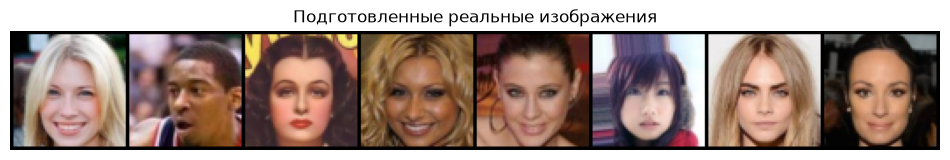

In [12]:
if MODE != 'generate':
    train_paths, val_paths, manifest, data_fingerprint = prepare_face_paths(
        DATA_SOURCE, DATA_DIR, FACES_DIR, MAX_TRAIN_IMAGES, MAX_VAL_IMAGES, SEED)
    cache_bytes = (len(train_paths) + len(val_paths)) * 3 * IMAGE_SIZE * IMAGE_SIZE
    if CACHE_IMAGES and cache_bytes > MAX_CACHE_GIB * 1024**3:
        raise MemoryError(f'Кеш требует {cache_bytes / 1024**3:.2f} GiB. '
                          'Увеличьте MAX_CACHE_GIB при наличии RAM или отключите CACHE_IMAGES.')
    dataset_class = CachedFaceFiles if CACHE_IMAGES else FaceFiles
    train_set = dataset_class(train_paths, IMAGE_SIZE, training=True, celeba_crop=DATA_SOURCE == 'celeba')
    val_set = dataset_class(val_paths, IMAGE_SIZE, celeba_crop=DATA_SOURCE == 'celeba')
    print('Кеш изображений, MiB:', cache_bytes / 1024**2 if CACHE_IMAGES else 0)
    loader_rng = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                              generator=loader_rng, pin_memory=DEVICE.type == 'cuda')
    val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
                            generator=torch.Generator().manual_seed(SEED + 100),
                            pin_memory=DEVICE.type == 'cuda')
    print('Обучение:', len(train_set), '| Проверка:', len(val_set))
    examples = torch.stack([val_set[i] for i in range(min(8, len(val_set)))])
    plt.figure(figsize=(12, 3))
    from torchvision.utils import make_grid
    plt.imshow(make_grid((examples + 1) / 2, nrow=8).permute(1, 2, 0))
    plt.axis('off')
    plt.title('Подготовленные реальные изображения')
    plt.show()
else:
    print('Режим генерации: датасет не загружается.')

## 6. U-Net и обёртка EDM

U-Net учится на примерах и изменяет свои веса. Обёртка EDM вычисляет коэффициенты
масштабирования и превращает выход сети в оценку чистого изображения `D(x, sigma)`.
Для RGB вход и выход имеют **3 канала**. Меток цифр и классов здесь нет.

При `64×64` сеть обрабатывает уровни `64 → 32 → 16 → 8` и восстанавливает разрешение.
Attention включён на небольших разрешениях, чтобы уменьшить расход памяти.
`SIGMA_DATA = 0.5` — фиксированный параметр масштабирования EDM для нормализованных изображений.

AMP применяется только к U-Net. Формулы EDM вычисляются в FP32. Attention использует
ту же формулу, что исходный NVIDIA-код; внутри softmax и его обратного прохода autocast
явно выключен, чтобы FP16 не переопределял вычисления с float32-входами.
`DEBUG_CHECKS=True` включает проверку значений sigma в каждом forward; в обычном режиме
проверяется форма, а контроль устойчивости выполняется на границе обновления весов.


In [47]:
class FP32AttentionOp(torch.autograd.Function):
    """Original EDM attention formula, with autocast explicitly disabled inside it."""
    @staticmethod
    def forward(ctx, q, k):
        with torch.autocast(device_type=q.device.type, enabled=False):
            weights = torch.einsum('ncq,nck->nqk', q.float(),
                                  (k / math.sqrt(k.shape[1])).float()).softmax(dim=2).to(q.dtype)
        ctx.save_for_backward(q, k, weights)
        return weights

    @staticmethod
    def backward(ctx, grad_weights):
        q, k, weights = ctx.saved_tensors
        with torch.autocast(device_type=q.device.type, enabled=False):
            # Производная softmax без обращения к приватной _softmax_backward_data.
            w, dw = weights.float(), grad_weights.float()
            logits_grad = w * (dw - (dw * w).sum(dim=2, keepdim=True))
            dq = torch.einsum('nck,nqk->ncq', k.float(), logits_grad) / math.sqrt(k.shape[1])
            dk = torch.einsum('ncq,nqk->nck', q.float(), logits_grad) / math.sqrt(k.shape[1])
        return dq.to(q.dtype), dk.to(k.dtype)

# Меняется только отдельный модуль optimized в текущем ядре.
edm_networks.AttentionOp = FP32AttentionOp

class FaceEDM(nn.Module):
    def __init__(self, image_size=64, model_channels=64, channel_mult=(1, 2, 3, 4),
                 num_blocks=2, attention_resolutions=(16, 8), dropout=0.1, sigma_data=0.5):
        super().__init__()
        self.config = dict(image_size=image_size, model_channels=model_channels,
                           channel_mult=list(channel_mult), num_blocks=num_blocks,
                           attention_resolutions=list(attention_resolutions),
                           dropout=dropout, sigma_data=sigma_data)
        self.amp_enabled = False
        self.debug_checks = False
        self.image_size = image_size
        self.sigma_data = sigma_data
        self.net = DhariwalUNet(
            img_resolution=image_size, in_channels=3, out_channels=3, label_dim=0,
            model_channels=model_channels, channel_mult=list(channel_mult),
            num_blocks=num_blocks, attn_resolutions=list(attention_resolutions), dropout=dropout)

    def forward(self, x, sigma):
        sigma = torch.as_tensor(sigma, dtype=torch.float32, device=x.device).reshape(-1, 1, 1, 1)
        if sigma.numel() not in (1, x.shape[0]):
            raise ValueError('sigma: один уровень или по одному на изображение.')
        if self.debug_checks and not torch.all(torch.isfinite(sigma) & (sigma > 0)):
            raise ValueError('sigma должен быть конечным и положительным.')
        sigma = sigma.expand(x.shape[0], 1, 1, 1)
        data2 = self.sigma_data ** 2
        c_skip = data2 / (data2 + sigma.square())
        c_out = self.sigma_data * sigma / (data2 + sigma.square()).sqrt()
        c_in = (data2 + sigma.square()).rsqrt()
        c_noise = sigma.log() / 4
        # Веса остаются FP32. Только U-Net использует autocast; EDM и loss остаются FP32.
        with torch.autocast(device_type=x.device.type, dtype=torch.float16,
                            enabled=self.amp_enabled and x.device.type == 'cuda'):
            prediction = self.net(c_in * x, c_noise.flatten(), None)
        prediction = prediction.float()
        return c_skip * x + c_out * prediction

## 7. Ошибка и EMA

Берём настоящее лицо, добавляем `sigma × noise`, просим модель восстановить исходное
изображение и считаем взвешенную среднеквадратичную ошибку. Уровни шума меняются для
каждого примера: `sigma = exp(P_MEAN + P_STD × normal_noise)`.
Параметры распределения шума взяты из исходного EDM.

**EMA** — дополнительная копия весов, которая плавно усредняет обновления обучаемой сети.
Её используем для проверки и генерации. В начале коэффициент сглаживания нарастает,
чтобы копия не оставалась слишком долго рядом со случайными начальными весами.

EMA обновляется групповым `foreach_lerp_` только после успешного шага Adam. При переполнении
FP16 шаг пропускается, GradScaler уменьшает масштаб, счётчик успешных обновлений и EMA
не меняются. Проверка нормы градиентов остаётся на каждом обновлении ради устойчивости.
Метрики суммируются на устройстве в float64, без хранения графа вычислений.


In [48]:
def face_loss(model, clean, p_mean=-1.2, p_std=1.2, generator=None):
    sigma = (p_mean + p_std * torch.randn((len(clean), 1, 1, 1), device=clean.device,
                                         generator=generator)).exp()
    noise = torch.randn(clean.shape, device=clean.device, generator=generator)
    denoised = model(clean + sigma * noise, sigma)
    weight = (sigma.square() + model.sigma_data**2) / (sigma * model.sigma_data).square()
    return (weight * (denoised - clean).square()).mean()

@torch.no_grad()
def update_ema(ema, model, step, decay):
    effective_decay = min(decay, (1 + step) / (10 + step))
    if USE_FOREACH:
        torch._foreach_lerp_(list(ema.parameters()), list(model.parameters()), 1 - effective_decay)
    else:
        for averaged, current in zip(ema.parameters(), model.parameters()):
            averaged.lerp_(current, 1 - effective_decay)
    for averaged, current in zip(ema.buffers(), model.buffers()):
        averaged.copy_(current)

@torch.inference_mode()
def evaluate_faces(model, loader, device, p_mean, p_std):
    model.eval()
    rng = torch.Generator(device=device).manual_seed(12345)
    total, count = torch.zeros((), device=device, dtype=torch.float64), 0
    for images in loader:
        images = images.to(device)
        loss = face_loss(model, images, p_mean, p_std, generator=rng)
        total.add_(loss.detach().double() * len(images))
        count += len(images)
    result = (total / count).item()
    if not math.isfinite(result):
        raise FloatingPointError('Проверочный loss не является конечным числом.')
    return result


def optimizer_options(device, implementation):
    selected = ('fused' if device.type == 'cuda' else 'foreach') if implementation == 'auto' else implementation
    if selected == 'fused' and device.type != 'cuda':
        raise ValueError('Выберите foreach/standard для CPU.')
    return dict(fused=selected == 'fused', foreach=selected == 'foreach')


def apply_update(model, optimizer, scaler, group_seen):
    """Normalize and clip a complete accumulated group; report whether weights changed."""
    if group_seen <= 0:
        raise ValueError('Нельзя обновлять веса без изображений.')
    # unscale вызывается ровно один раз, после всех backward данной группы.
    scaler.unscale_(optimizer)
    parameters = [p for p in model.parameters() if p.grad is not None]
    gradients = [p.grad for p in parameters]
    if not gradients:
        raise RuntimeError('У модели отсутствуют градиенты.')
    if USE_FOREACH:
        torch._foreach_div_(gradients, group_seen)
    else:
        for gradient in gradients:
            gradient.div_(group_seen)
    norm = torch.nn.utils.clip_grad_norm_(parameters, 1.0, foreach=USE_FOREACH,
                                         error_if_nonfinite=False)
    # Одна необходимая проверка на группу, а не несколько ожиданий в каждом forward/batch.
    if not torch.isfinite(norm):
        if not scaler.is_enabled():
            raise FloatingPointError('Градиенты или их норма не конечны; веса не обновлены.')
        new_scale = scaler.get_scale() * scaler.get_backoff_factor()
        if not math.isfinite(new_scale) or new_scale <= 0:
            raise FloatingPointError('Масштаб AMP исчерпан. Проверьте данные/LR или выключите USE_AMP.')
        scaler.update(new_scale=new_scale)
        optimizer.zero_grad(set_to_none=True)
        return False
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    return True


## 8. Генерация из шума

Начальная картинка — независимый RGB-шум `[count, 3, H, W]`. Постепенно уменьшаем `sigma`.
Метод Эйлера делает один прогноз на шаг. Метод Хойна (`solver='heun'`) дополнительно
оценивает направление в конце шага и усредняет два направления; обычно он позволяет
точнее пройти траекторию при том же числе уровней шума, но вызывает сеть почти вдвое чаще.
На последнем шаге к нулю используется только Эйлер: `log(0)` в сеть не подаётся.

Для показа переводим результат из `[-1,1]` в `[0,1]` и обрезаем выход за границы.
Внутри процесса генерации такое обрезание не применяется.

In [49]:
@torch.inference_mode()
def sample_faces(model, count=8, steps=40, seed=123, solver='heun', sigma_min=0.002,
                 sigma_max=80.0, rho=7.0, batch_size=4):
    if min(count, batch_size) < 1 or steps < 2 or not 0 < sigma_min < sigma_max or rho <= 0:
        raise ValueError('Проверьте count, batch_size, steps и границы sigma.')
    if solver not in {'euler', 'heun'}:
        raise ValueError('solver должен быть euler или heun.')
    model.eval()
    device = next(model.parameters()).device
    rng = torch.Generator(device=device).manual_seed(seed)
    ramp = torch.linspace(0, 1, steps, device=device)
    levels = (sigma_max**(1/rho) + ramp * (sigma_min**(1/rho) - sigma_max**(1/rho)))**rho
    levels = torch.cat([levels, levels.new_zeros(1)])
    results = []
    for start in range(0, count, batch_size):
        n = min(batch_size, count - start)
        x = torch.randn((n, 3, model.image_size, model.image_size), device=device,
                         generator=rng) * sigma_max
        for index in range(steps):
            current, following = levels[index], levels[index + 1]
            drift = (x - model(x, current)) / current
            proposal = x + (following - current) * drift
            if solver == 'heun' and index < steps - 1:
                next_drift = (proposal - model(proposal, following)) / following
                x = x + (following - current) * (drift + next_drift) / 2
            else:
                x = proposal
        if not torch.isfinite(x).all():
            raise FloatingPointError('Генерация дала NaN/Inf. Проверьте веса и параметры.')
        results.append(x.cpu())
    return torch.cat(results)

def save_faces(images, path, columns=4):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    save_image((images.detach().cpu() / 2 + 0.5).clamp(0, 1), path, nrow=columns)

## 9. Сохранение и восстановление

`last.pth` содержит исходную сеть, EMA, Adam, историю эпох, генераторы случайных чисел
и описание данных. `ema_weights.pth` — компактный файл только для генерации.
Запись сначала идёт во временный файл, затем файл заменяет предыдущую версию.
Для загрузки используется `torch.load(..., weights_only=True)`.

При resume проверяются конфигурация и отпечаток датасета. Продолжать нужно с теми же
данными и seed; путь к папке можно изменить. Сохранены состояния RNG для PyTorch и
перемешивания данных. Побитовая воспроизводимость между разными GPU/версиями не гарантируется.

Новый `last.pth` имеет формат `faces-edm-v2` и дополнительно хранит GradScaler и число
пропущенных AMP-обновлений. Optimized notebook читает оба формата v1/v2: можно продолжить
с `last.pth` исходного notebook, начав scaler с начального состояния.
Продолжайте v2 именно в optimized notebook; исходная версия v2 не понимает.
Архитектура и имена весов совместимы. EMA-файл остаётся компактным и предназначен для генерации.


In [50]:
def cpu_state(model):
    return {key: value.detach().cpu() for key, value in model.state_dict().items()}

def atomic_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)

def save_training(path, model, ema, optimizer, epoch, global_step, history,
                  train_config, data_fingerprint, loader_rng, scaler, skipped_updates):
    atomic_save(dict(format_version='faces-edm-v2', kind='training', model_config=model.config,
                     model_state=cpu_state(model), ema_state=cpu_state(ema),
                     optimizer_state=optimizer.state_dict(), epoch=epoch, global_step=global_step,
                     history=history, train_config=train_config, data_fingerprint=data_fingerprint,
                     scaler_state=scaler.state_dict(), amp_enabled=AMP_ENABLED,
                     skipped_updates=skipped_updates,
                     optimization_config=dict(use_foreach=USE_FOREACH, optimizer_impl=OPTIMIZER_IMPL,
                                              cache_images=CACHE_IMAGES, log_every=LOG_EVERY),
                     torch_rng=torch.get_rng_state(), loader_rng=loader_rng.get_state(),
                     cuda_rng=torch.cuda.get_rng_state_all() if DEVICE.type == 'cuda' else [],
                     torch_version=str(torch.__version__)), path)

def read_face_checkpoint(path):
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    if checkpoint.get('format_version') not in {'faces-edm-v1', 'faces-edm-v2'}:
        raise ValueError('Нужен checkpoint этого ноутбука для лиц. Веса MNIST не подходят.')
    return checkpoint

def load_face_generator(path, device):
    checkpoint = read_face_checkpoint(path)
    net = FaceEDM(**checkpoint['model_config'])
    net.load_state_dict(checkpoint['ema_state'], strict=True)
    net.amp_enabled = bool(USE_AMP and device.type == 'cuda')
    net.debug_checks = DEBUG_CHECKS
    return net.to(device).eval()

## 10. Создание модели или продолжение

В режиме `train` все веса инициализируются заново. В режиме `resume` загружаются Ваши
собственные веса и состояние Adam; модель продолжает учиться с уже достигнутого состояния.
Повторный запуск ячейки обучения после её завершения специально блокируется:
для продолжения выберите `resume` и выполните ноутбук заново.

In [51]:
if MODE != 'generate':
    model_config = dict(image_size=IMAGE_SIZE, model_channels=MODEL_CHANNELS,
                        channel_mult=CHANNEL_MULT, num_blocks=NUM_BLOCKS,
                        attention_resolutions=ATTENTION_RESOLUTIONS, dropout=DROPOUT,
                        sigma_data=SIGMA_DATA)
    train_config = dict(seed=SEED, learning_rate=LEARNING_RATE, ema_decay=EMA_DECAY,
                        p_mean=P_MEAN, p_std=P_STD, data_source=DATA_SOURCE,
                        max_train=MAX_TRAIN_IMAGES, max_val=MAX_VAL_IMAGES)
    if MODE == 'train' and (RUN_DIR / 'last.pth').exists():
        raise FileExistsError('В папке уже есть веса. Выберите resume или создайте новый запуск.')
    model = FaceEDM(**model_config).to(DEVICE)
    model.amp_enabled = AMP_ENABLED
    model.debug_checks = DEBUG_CHECKS
    ema = copy.deepcopy(model).eval().requires_grad_(False)
    selected_optimizer_options = optimizer_options(DEVICE, OPTIMIZER_IMPL)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, **selected_optimizer_options)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP_ENABLED, init_scale=1024.0)
    skipped_updates = 0
    start_epoch, global_step, history = 0, 0, []
    if MODE == 'resume':
        checkpoint = read_face_checkpoint(CHECKPOINT_PATH)
        if checkpoint.get('kind') != 'training':
            raise ValueError('Для продолжения нужен last.pth со состоянием оптимизатора.')
        if checkpoint['model_config'] != model_config or checkpoint['train_config'] != train_config:
            raise ValueError('Настройки не совпадают с checkpoint. Сверьтесь с config.json исходного запуска.')
        if checkpoint['data_fingerprint'] != data_fingerprint:
            raise ValueError('Изменились фотографии или разбиение. Для resume нужен исходный датасет.')
        model.load_state_dict(checkpoint['model_state'])
        ema.load_state_dict(checkpoint['ema_state'])
        optimizer_state = checkpoint['optimizer_state']
        # load_state_dict иначе вернёт старые foreach/fused-флаги из checkpoint.
        for group in optimizer_state['param_groups']:
            group.update(selected_optimizer_options)
        optimizer.load_state_dict(optimizer_state)
        if AMP_ENABLED and checkpoint.get('scaler_state'):
            scaler.load_state_dict(checkpoint['scaler_state'])
        skipped_updates = checkpoint.get('skipped_updates', 0)
        if checkpoint.get('amp_enabled', False) != AMP_ENABLED:
            print('Режим точности изменился: обучение продолжается, побитовое совпадение не ожидается.')
        start_epoch, global_step, history = checkpoint['epoch'], checkpoint['global_step'], checkpoint['history']
        torch.set_rng_state(checkpoint['torch_rng'])
        loader_rng.set_state(checkpoint['loader_rng'])
        if DEVICE.type == 'cuda' and len(checkpoint['cuda_rng']) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(checkpoint['cuda_rng'])
        del checkpoint
    if EPOCHS <= start_epoch:
        raise ValueError(f'Уже завершено {start_epoch} эпох. Установите EPOCHS больше этого числа.')
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    config = dict(model=model_config, training=train_config, batch_size=BATCH_SIZE,
                  accumulation_steps=ACCUMULATION_STEPS, target_epochs=EPOCHS,
                  data_fingerprint=data_fingerprint, torch_version=str(torch.__version__),
                  optimization=dict(amp=AMP_ENABLED, cache_images=CACHE_IMAGES, use_foreach=USE_FOREACH,
                                    optimizer_impl=OPTIMIZER_IMPL, log_every=LOG_EVERY))
    (RUN_DIR / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    (RUN_DIR / 'data_split.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    print('Параметров U-Net:', f'{sum(p.numel() for p in model.parameters()):,}')
    print('Продолжаем после эпохи:', start_epoch, '| шагов оптимизатора:', global_step)
    print('Adam:', selected_optimizer_options, '| AMP:', AMP_ENABLED)
    training_started = False
else:
    print('Модель для генерации будет загружена ниже.')

Параметров U-Net: 25,117,699
Продолжаем после эпохи: 30 | шагов оптимизатора: 28131
Adam: {'fused': True, 'foreach': False} | AMP: True


## 11. Обучение

Для каждого небольшого пакета вычисляем ошибку и градиенты. После нескольких пакетов
усредняем накопленные градиенты по фактическому числу изображений, ограничиваем их норму
и выполняем шаг Adam. Затем обновляем EMA.

После эпохи считаем проверочный loss EMA, сохраняем `last.pth`, компактные веса,
таблицу метрик и сетку генераций с фиксированным seed. Сравнение картинок между эпохами
показывает, как меняется именно модель. Эти картинки начинаются с шума, а не с фотографий.

Если сессия прервётся посреди эпохи, сохранение предыдущей эпохи останется пригодным
для продолжения. Для повторного старта после ошибки переключитесь в `resume` и перезапустите
ноутбук; если ни одна эпоха ещё не сохранена, начните новый `train`.

В optimized версии сумма ошибок остаётся на GPU; `loss.item()` на каждом пакете отсутствует.
Текст прогресса обновляется каждые `LOG_EVERY` пакетов и в конце эпохи. Строка `amp_skips`
показывает общее число пропущенных обновлений из-за переполнения. Несколько первых
пропусков возможны при подборе масштаба; постоянный рост требует проверки устойчивости.
Количество сохранений, preview и проверочных проходов не менялось.


Эпоха 31/60:   0%|          | 0/7500 [00:00<?, ?it/s]

Эпоха 31/60: 100%|██████████| 7500/7500 [13:21<00:00,  9.36it/s, amp_skips=11, loss=0.1049, updates=29067]


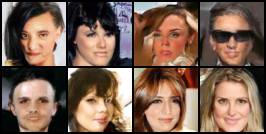

Эпоха 31: train=0.1049, val EMA=0.1006, обучение + проверка: 13.7 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 32/60: 100%|██████████| 7500/7500 [13:22<00:00,  9.35it/s, amp_skips=11, loss=0.1041, updates=3e+4] 


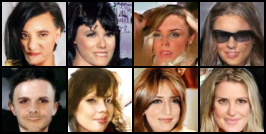

Эпоха 32: train=0.1041, val EMA=0.1005, обучение + проверка: 13.7 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 33/60: 100%|██████████| 7500/7500 [13:23<00:00,  9.33it/s, amp_skips=11, loss=0.1043, updates=30943]


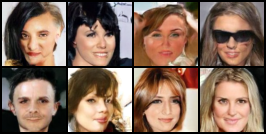

Эпоха 33: train=0.1043, val EMA=0.1003, обучение + проверка: 13.7 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 34/60: 100%|██████████| 7500/7500 [13:22<00:00,  9.34it/s, amp_skips=12, loss=0.1046, updates=31880]


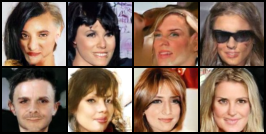

Эпоха 34: train=0.1046, val EMA=0.1002, обучение + проверка: 13.7 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 35/60: 100%|██████████| 7500/7500 [13:24<00:00,  9.33it/s, amp_skips=12, loss=0.1042, updates=32818]


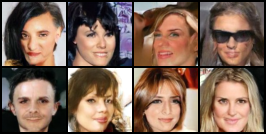

Эпоха 35: train=0.1042, val EMA=0.1001, обучение + проверка: 13.7 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 36/60: 100%|██████████| 7500/7500 [13:13<00:00,  9.45it/s, amp_skips=12, loss=0.1033, updates=33756]


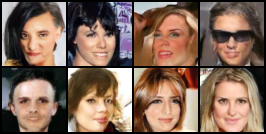

Эпоха 36: train=0.1033, val EMA=0.1000, обучение + проверка: 13.5 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 37/60: 100%|██████████| 7500/7500 [13:18<00:00,  9.39it/s, amp_skips=13, loss=0.1036, updates=34693]


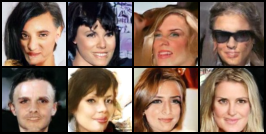

Эпоха 37: train=0.1036, val EMA=0.0999, обучение + проверка: 13.6 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 38/60: 100%|██████████| 7500/7500 [13:10<00:00,  9.49it/s, amp_skips=13, loss=0.1036, updates=35631]


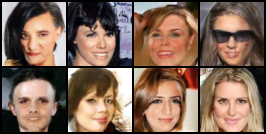

Эпоха 38: train=0.1036, val EMA=0.0998, обучение + проверка: 13.5 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 39/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=14, loss=0.1034, updates=36568]


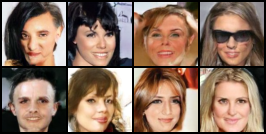

Эпоха 39: train=0.1034, val EMA=0.0997, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 40/60: 100%|██████████| 7500/7500 [13:09<00:00,  9.50it/s, amp_skips=15, loss=0.1035, updates=37505]


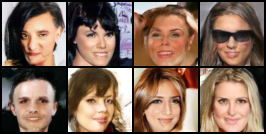

Эпоха 40: train=0.1035, val EMA=0.0996, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 41/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=15, loss=0.1029, updates=38443]


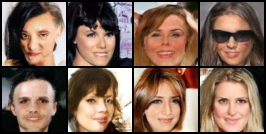

Эпоха 41: train=0.1029, val EMA=0.0997, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 42/60: 100%|██████████| 7500/7500 [13:07<00:00,  9.52it/s, amp_skips=16, loss=0.1037, updates=39380]


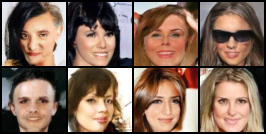

Эпоха 42: train=0.1037, val EMA=0.0995, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 43/60: 100%|██████████| 7500/7500 [13:07<00:00,  9.53it/s, amp_skips=16, loss=0.1027, updates=40318]


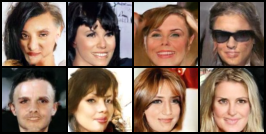

Эпоха 43: train=0.1027, val EMA=0.0994, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 44/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=16, loss=0.1024, updates=41256]


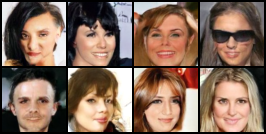

Эпоха 44: train=0.1024, val EMA=0.0993, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 45/60: 100%|██████████| 7500/7500 [13:10<00:00,  9.49it/s, amp_skips=16, loss=0.1025, updates=42194]


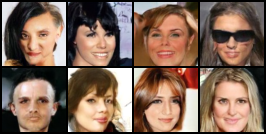

Эпоха 45: train=0.1025, val EMA=0.0993, обучение + проверка: 13.5 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 46/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=16, loss=0.1033, updates=43132]


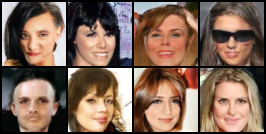

Эпоха 46: train=0.1033, val EMA=0.0992, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 47/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=17, loss=0.1027, updates=44069]


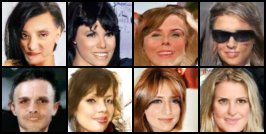

Эпоха 47: train=0.1027, val EMA=0.0991, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 48/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=19, loss=0.1020, updates=45005]


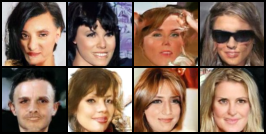

Эпоха 48: train=0.1020, val EMA=0.0991, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 49/60: 100%|██████████| 7500/7500 [13:07<00:00,  9.52it/s, amp_skips=19, loss=0.1023, updates=45943]


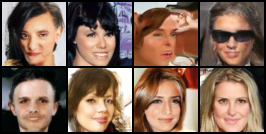

Эпоха 49: train=0.1023, val EMA=0.0990, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 50/60: 100%|██████████| 7500/7500 [13:07<00:00,  9.52it/s, amp_skips=19, loss=0.1026, updates=46881]


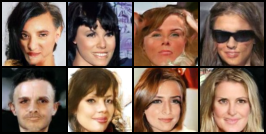

Эпоха 50: train=0.1026, val EMA=0.0991, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 51/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.52it/s, amp_skips=19, loss=0.1009, updates=47819]


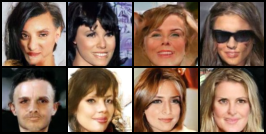

Эпоха 51: train=0.1009, val EMA=0.0990, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 52/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.51it/s, amp_skips=20, loss=0.1021, updates=48756]


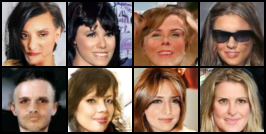

Эпоха 52: train=0.1021, val EMA=0.0989, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 53/60: 100%|██████████| 7500/7500 [13:08<00:00,  9.52it/s, amp_skips=20, loss=0.1024, updates=49694]


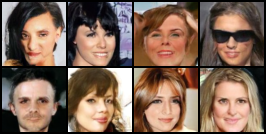

Эпоха 53: train=0.1024, val EMA=0.0988, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 54/60: 100%|██████████| 7500/7500 [13:09<00:00,  9.50it/s, amp_skips=21, loss=0.1019, updates=50631]


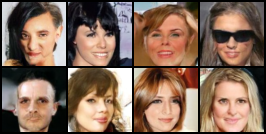

Эпоха 54: train=0.1019, val EMA=0.0988, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 55/60: 100%|██████████| 7500/7500 [13:07<00:00,  9.52it/s, amp_skips=21, loss=0.1020, updates=51569]


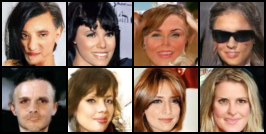

Эпоха 55: train=0.1020, val EMA=0.0987, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 56/60: 100%|██████████| 7500/7500 [13:07<00:00,  9.53it/s, amp_skips=22, loss=0.1019, updates=52506]


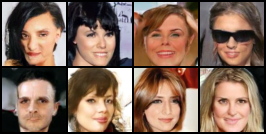

Эпоха 56: train=0.1019, val EMA=0.0987, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 57/60: 100%|██████████| 7500/7500 [13:24<00:00,  9.32it/s, amp_skips=22, loss=0.1017, updates=53444]


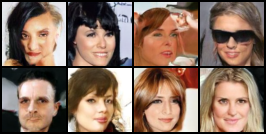

Эпоха 57: train=0.1017, val EMA=0.0986, обучение + проверка: 13.7 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 58/60: 100%|██████████| 7500/7500 [13:06<00:00,  9.53it/s, amp_skips=22, loss=0.1012, updates=54382]


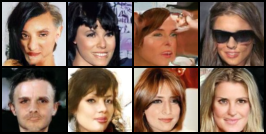

Эпоха 58: train=0.1012, val EMA=0.0987, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 59/60: 100%|██████████| 7500/7500 [13:03<00:00,  9.57it/s, amp_skips=23, loss=0.1022, updates=55319]


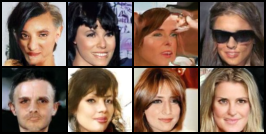

Эпоха 59: train=0.1022, val EMA=0.0986, обучение + проверка: 13.4 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


Эпоха 60/60: 100%|██████████| 7500/7500 [13:03<00:00,  9.58it/s, amp_skips=23, loss=0.1019, updates=56257]


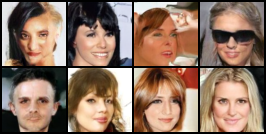

Эпоха 60: train=0.1019, val EMA=0.0986, обучение + проверка: 13.3 мин.
Сохранено: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


In [52]:
if MODE != 'generate':
    if training_started:
        raise RuntimeError('Эта попытка обучения уже запускалась. Используйте MODE=resume и перезапуск ноутбука.')
    training_started = True
    for epoch in range(start_epoch + 1, EPOCHS + 1):
        began = time.perf_counter()
        model.train()
        optimizer.zero_grad(set_to_none=True)
        total = torch.zeros((), device=DEVICE, dtype=torch.float64)
        seen, group_seen = 0, 0
        progress = tqdm(train_loader, desc=f'Эпоха {epoch}/{EPOCHS}')
        for batch_index, images in enumerate(progress, 1):
            clean = images.to(DEVICE, non_blocking=True)
            loss = face_loss(model, clean, P_MEAN, P_STD)
            scaler.scale(loss * len(clean)).backward()
            total.add_(loss.detach().double() * len(clean))
            seen += len(clean)
            group_seen += len(clean)
            if batch_index % ACCUMULATION_STEPS == 0 or batch_index == len(train_loader):
                updated = apply_update(model, optimizer, scaler, group_seen)
                if updated:
                    global_step += 1
                    update_ema(ema, model, global_step, EMA_DECAY)
                else:
                    skipped_updates += 1
                group_seen = 0
            if batch_index % LOG_EVERY == 0 or batch_index == len(train_loader):
                average_loss = (total / seen).item()
                if not math.isfinite(average_loss):
                    raise FloatingPointError('Loss стал NaN/Inf. Проверьте данные, LR и режим AMP.')
                progress.set_postfix(loss=f'{average_loss:.4f}', updates=global_step,
                                     amp_skips=skipped_updates)
        val_loss = evaluate_faces(ema, val_loader, DEVICE, P_MEAN, P_STD)
        metrics = dict(epoch=epoch, global_step=global_step, train_loss=average_loss,
                       val_ema_loss=val_loss, seconds=time.perf_counter() - began)
        history.append(metrics)
        save_training(RUN_DIR / 'last.pth', model, ema, optimizer, epoch, global_step,
                      history, train_config, data_fingerprint, loader_rng, scaler, skipped_updates)
        atomic_save(dict(format_version='faces-edm-v1', kind='ema', model_config=ema.config,
                         ema_state=cpu_state(ema), epoch=epoch), RUN_DIR / 'ema_weights.pth')
        with (RUN_DIR / 'metrics.csv').open('w', newline='', encoding='utf-8') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(metrics))
            writer.writeheader()
            writer.writerows(history)
        preview = sample_faces(ema, count=PREVIEW_COUNT, steps=PREVIEW_STEPS,
                               batch_size=PREVIEW_BATCH_SIZE, seed=100)
        preview_path = RUN_DIR / f'epoch_{epoch:03d}.png'
        save_faces(preview, preview_path)
        display(DisplayImage(filename=str(preview_path), width=600))
        print(f'Эпоха {epoch}: train={metrics["train_loss"]:.4f}, '
              f'val EMA={val_loss:.4f}, обучение + проверка: {metrics["seconds"]/60:.1f} мин.')
        print('Сохранено:', RUN_DIR / 'last.pth')

## 12. График обучения

Train loss относится к обучаемой сети с аугментацией и dropout; val loss — к EMA без них.
Поэтому кривые не обязаны совпадать. Рост проверочной ошибки при снижении обучающей
может указывать на переобучение. Оценивайте также разнообразие и качество генераций.

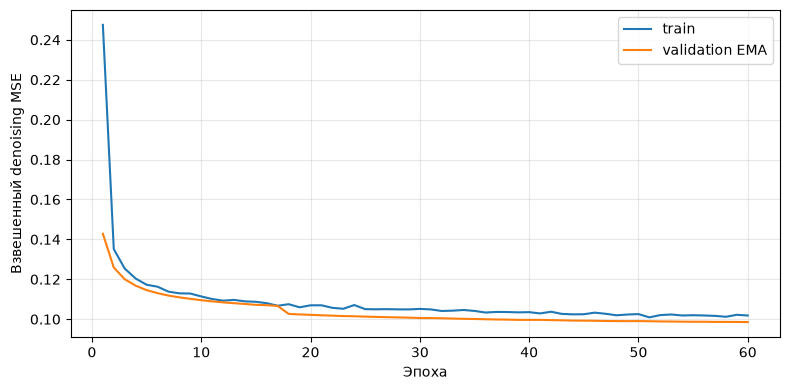

In [53]:
if MODE != 'generate' and history:
    plt.figure(figsize=(8, 4))
    plt.plot([row['epoch'] for row in history], [row['train_loss'] for row in history], label='train')
    plt.plot([row['epoch'] for row in history], [row['val_ema_loss'] for row in history], label='validation EMA')
    plt.xlabel('Эпоха')
    plt.ylabel('Взвешенный denoising MSE')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUN_DIR / 'loss.png', dpi=150)
    plt.show()

## 13. Загрузить собственные веса для генерации

После обучения берём EMA из `last.pth`. В режиме `generate` используется `CHECKPOINT_PATH`.
Архитектура восстанавливается из файла, поэтому для генерации не требуется вручную
повторять размеры модели в настройках. Обучаемая сеть и Adam освобождаются из памяти.

In [54]:
selected_checkpoint = Path(CHECKPOINT_PATH) if MODE == 'generate' else RUN_DIR / 'last.pth'
for name in ('model', 'ema', 'optimizer', 'scaler', 'clean', 'loss'):
    globals().pop(name, None)
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
generator_model = load_face_generator(selected_checkpoint, DEVICE)
RUN_DIR.mkdir(parents=True, exist_ok=True)
print('Загружены Ваши EMA-веса:', selected_checkpoint)

Загружены Ваши EMA-веса: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\last.pth


## 14. Сгенерировать лица

Меняйте `GENERATION_SEED`, чтобы получить новые изображения. При том же seed, настройках,
весах и окружении результат воспроизводится. `GENERATION_BATCH_SIZE` ограничивает расход
видеопамяти при генерации; для точного сравнения сохраняйте и его.
Эту ячейку можно выполнять многократно. Каждый запуск сохраняется в отдельную папку.

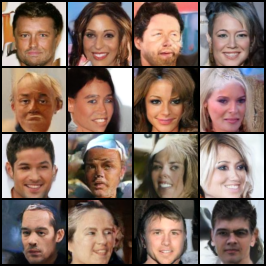

Сетка и отдельные PNG: C:\projects\diffusion-model\runs\faces_optimized\20261101_221330_23642a\generation_1ed7a6cc


In [57]:
COUNT = 16
GENERATION_SEED = 999
GENERATION_STEPS = 200
GENERATION_BATCH_SIZE = 4
SOLVER = 'heun'                      # можно 'euler' для сравнения

generated = sample_faces(generator_model, count=COUNT, steps=GENERATION_STEPS,
                         seed=GENERATION_SEED, solver=SOLVER, batch_size=GENERATION_BATCH_SIZE)
generation_dir = RUN_DIR / ('generation_' + uuid4().hex[:8])
generation_dir.mkdir(parents=True)
save_faces(generated, generation_dir / 'grid.png')
for index, face in enumerate(generated):
    save_faces(face, generation_dir / f'face_{index:03d}.png', columns=1)
settings = dict(seed=GENERATION_SEED, steps=GENERATION_STEPS, solver=SOLVER, count=COUNT,
                batch_size=GENERATION_BATCH_SIZE, checkpoint=str(selected_checkpoint),
                model=generator_model.config)
(generation_dir / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
display(DisplayImage(filename=str(generation_dir / 'grid.png'), width=600))
print('Сетка и отдельные PNG:', generation_dir)

## 15. Посмотреть работу денойзера

Здесь используется настоящее проверочное изображение: добавляем шум и показываем
восстановление. Это демонстрация удаления шума, отдельная от генерации лиц с нуля выше.

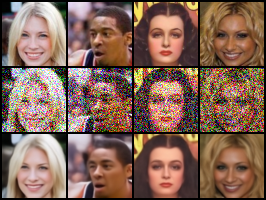

Строки: оригинал, зашумлённое изображение, восстановление.


In [34]:
if MODE != 'generate':
    demo_clean = torch.stack([val_set[i] for i in range(min(4, len(val_set)))]).to(DEVICE)
    demo_rng = torch.Generator(device=DEVICE).manual_seed(17)
    demo_noisy = demo_clean + 0.5 * torch.randn(demo_clean.shape, device=DEVICE, generator=demo_rng)
    with torch.inference_mode():
        demo_restored = generator_model(demo_noisy, 0.5)
    save_faces(torch.cat([demo_clean, demo_noisy, demo_restored]), RUN_DIR / 'denoising.png',
               columns=len(demo_clean))
    display(DisplayImage(filename=str(RUN_DIR / 'denoising.png'), width=600))
    print('Строки: оригинал, зашумлённое изображение, восстановление.')

## 16. Скачать результаты и продолжить позже

Установите `DOWNLOAD_RESULTS = True`, чтобы собрать ZIP. Архив содержит Ваши веса,
метрики, настройки, сгенерированные картинки и исходный код U-Net с лицензией.
Датасет в архив не включается. **Сохраните также этот notebook**: его определения нужны
для восстановления обёртки модели и продолжения обучения.

В новой сессии загрузите notebook и распакуйте результаты. Для продолжения выберите
`MODE = 'resume'`, укажите путь к `last.pth`, тот же датасет и настройки из `config.json`,
увеличьте `EPOCHS` и выполните ячейки по порядку. Для одной генерации используйте
`MODE = 'generate'` и путь к `ema_weights.pth` или `last.pth`.

Файл `last.pth` крупнее `ema_weights.pth`: в нём дополнительно сохранены обучаемая сеть и Adam.

Для восстановления v2 сохраните именно `Faces_Diffusion_Colab_optimized.ipynb` вместе с архивом.

In [ ]:
DOWNLOAD_RESULTS = False
if DOWNLOAD_RESULTS:
    shutil.copytree('vendor_faces_optimized', RUN_DIR / 'vendor_faces_optimized', dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns('__pycache__'))
    if MODE == 'generate':
        destination = RUN_DIR / selected_checkpoint.name
        if selected_checkpoint.resolve() != destination.resolve():
            shutil.copy2(selected_checkpoint, destination)
    (RUN_DIR / 'RESTORE.txt').write_text(
        'Keep Faces_Diffusion_Colab_optimized.ipynb with this archive.\n'
        'Resume: MODE=resume, CHECKPOINT_PATH=path/to/last.pth.\n'
        'Use the same dataset and settings from config.json; increase EPOCHS.\n'
        'Generate: MODE=generate, CHECKPOINT_PATH=path/to/ema_weights.pth or last.pth.\n',
        encoding='utf-8')
    archive = shutil.make_archive(str(RUN_DIR) + '_results', 'zip', root_dir=RUN_DIR)
    print('Архив:', archive)
    try:
        from google.colab import files
    except ImportError:
        print('Локальный запуск: архив готов по указанному пути.')
    else:
        files.download(archive)
else:
    print('Архив не запрошен. Все результаты находятся в:', RUN_DIR)

## Источники и границы проверки

- [NVIDIA EDM](https://github.com/NVlabs/edm): исходная архитектура, loss и лицензия.
- [AMP и накопление градиентов](https://docs.pytorch.org/docs/stable/notes/amp_examples.html).
- [Adam: foreach/fused](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html).
- [Рекомендации PyTorch по производительности](https://docs.pytorch.org/tutorials/recipes/recipes/tuning_guide).
- [CelebA](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html).

Ускорение зависит от GPU, версии PyTorch и данных. После изменения точности, реализации
оптимизатора и операций attention побитовое совпадение с исходной версией не гарантируется;
проверяйте конечность градиентов, loss и качество генерации.

Локальные CPU-проверки не заменяют испытание CUDA FP16/fused Adam на T4/RTX 2060,
облачного Colab, Google Drive и полного обучения на CelebA. Реальные замеры ускорения
на GPU в локальном окружении с CPU-сборкой PyTorch не выполняются.
